# Testy generátorů pseudonáhodných čísel

*Nad rámec cvičení — kapitola 4 skripta.*

---

V sešitu `ch04_generatory` jsme viděli, že RANDU má vadu, kterou dvourozměrný obrázek neukáže. Tady si pořídíme nástroje, které takové vady hledají **systematicky**, a pustíme je na tři generátory: dobrý, podezřelý a vyloženě špatný.

- jak vůbec funguje statistický test a co znamená, že generátor „prošel"
- **χ² test** jako společný základ
- **frekvenční** test (rovnoměrnost), **test sérií** (dvojice a trojice), **pokerový** test, **test běhů**, **autokorelační** test
- a hlavně: **který test co chytí** — každý vidí jinou vadu

Tohle je dolní hranice. Pro vážnou práci existují baterie jako TestU01 nebo Dieharder, které obsahují stovky testů.

In [1]:
import math
import random
from itertools import product

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def _gamma_P(a, x):
    """Regularizovaná dolní neúplná gama funkce P(a, x). Řada pro malé x, řetězový zlomek pro velké."""
    if x <= 0:
        return 0.0
    if x < a + 1.0:                       # rozvoj v řadu
        ap, soucet, clen = a, 1.0 / a, 1.0 / a
        for _ in range(500):
            ap += 1.0
            clen *= x / ap
            soucet += clen
            if abs(clen) < abs(soucet) * 1e-15:
                break
        return soucet * math.exp(-x + a * math.log(x) - math.lgamma(a))
    # řetězový zlomek pro Q(a, x) = 1 - P(a, x)
    tiny = 1e-300
    b, c, d = x + 1.0 - a, 1.0 / tiny, 1.0 / (x + 1.0 - a)
    h = d
    for i in range(1, 500):
        an = -i * (i - a)
        b += 2.0
        d = an * d + b
        if abs(d) < tiny:
            d = tiny
        c = b + an / c
        if abs(c) < tiny:
            c = tiny
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < 1e-15:
            break
    return 1.0 - math.exp(-x + a * math.log(x) - math.lgamma(a)) * h


def chi2_p(stat, df):
    """p-hodnota χ² testu: P(χ²_df > stat)."""
    return 1.0 - _gamma_P(df / 2.0, stat / 2.0)


def normal_p(z):
    """Oboustranná p-hodnota pro standardizovanou statistiku z."""
    return math.erfc(abs(z) / math.sqrt(2))


# kontrola proti tabulkovým kritickým hodnotám (p = 0.05)
for df, krit in ((1, 3.8415), (2, 5.9915), (5, 11.0705), (10, 18.3070), (50, 67.5048)):
    p = chi2_p(krit, df)
    assert abs(p - 0.05) < 1e-3, (df, p)
    print(f"χ² df = {df:>2}: kritická hodnota {krit:8.4f} -> p = {p:.4f}")
print("implementace χ² souhlasí s tabulkou")

χ² df =  1: kritická hodnota   3.8415 -> p = 0.0500
χ² df =  2: kritická hodnota   5.9915 -> p = 0.0500
χ² df =  5: kritická hodnota  11.0705 -> p = 0.0500
χ² df = 10: kritická hodnota  18.3070 -> p = 0.0500
χ² df = 50: kritická hodnota  67.5048 -> p = 0.0500
implementace χ² souhlasí s tabulkou


## 1. Jak se testuje generátor

Test má vždycky stejnou kostru:

1. **Nulová hypotéza $H_0$:** čísla jsou nezávislá a rovnoměrná na $[0,1)$.
2. **Statistika:** číslo spočítané z posloupnosti, jehož rozdělení za platnosti $H_0$ známe.
3. **p-hodnota:** pravděpodobnost, že by za platnosti $H_0$ statistika vyšla aspoň tak extrémní jako naměřená.
4. **Rozhodnutí:** malá p-hodnota (třeba pod $0.01$) znamená, že data s $H_0$ neladí.

Dvě věci, které se snadno pochopí špatně:

- **„Prošel testem" neznamená „je dobrý."** Znamená jen, že *tenhle* test tuhle vadu nevidí. RANDU projde frekvenčním testem bez zaváhání.
- **Hodně malá p-hodnota není jediný způsob, jak selhat.** Podezřelé je i p-hodnota příliš blízko jedničce — data sedí na teorii *lépe*, než by náhoda dovolila. Tak se poznají padělané výsledky.

Správně se test pouští mnohokrát na různých úsecích a p-hodnoty by samy měly vyjít rovnoměrně na $[0,1)$. Tomu se říká test druhého řádu a na konci sešitu si ho uděláme.

## 2. χ² test jako společný základ

Většina testů níž má stejný tvar: rozdělíme výsledky do $k$ tříd, porovnáme pozorované počty $O_i$ s očekávanými $E_i$ a spočítáme

$$\chi^2 = \sum_{i=1}^{k}\frac{(O_i - E_i)^2}{E_i}.$$

Za platnosti $H_0$ má $\chi^2$ přibližně rozdělení s $k - 1$ stupni volnosti (minus další stupeň za každý parametr odhadnutý z dat). Aproximace je použitelná, když je každé $E_i$ aspoň zhruba 5.

In [2]:
def chi2_test(pozorovane, ocekavane, df=None):
    """χ² statistika a p-hodnota pro dva seznamy stejné délky."""
    stat = sum((o - e) ** 2 / e for o, e in zip(pozorovane, ocekavane))
    if df is None:
        df = len(pozorovane) - 1
    return stat, chi2_p(stat, df)


# --- generátory, které budeme zkoušet ---

def mt(n):
    """Mersenne Twister (Pythonův random)."""
    return [random.random() for _ in range(n)]


def randu(n, seed=1):
    """RANDU: x <- 65539 x mod 2^31."""
    m, x, out = 2**31, seed, []
    for _ in range(n):
        x = (65539 * x) % m
        out.append(x / m)
    return out


def lcg_maly(n, seed=1):
    """Vyloženě špatný LCG: modul 2048, takže jen 2048 různých hodnot."""
    m, x, out = 2048, seed, []
    for _ in range(n):
        x = (1229 * x + 1) % m
        out.append(x / m)
    return out


GENERATORY = (("Mersenne Twister", mt), ("RANDU", randu), ("malý LCG (m = 2048)", lcg_maly))
N = 200_000
VZORKY = {nazev: f(N) for nazev, f in GENERATORY}
print(f"připraveno {format(N, ',').replace(',', ' ')} čísel od každého generátoru")

připraveno 200 000 čísel od každého generátoru


## 3. Frekvenční test

Nejjednodušší možný: rozdělíme $[0,1)$ na $k$ stejných přihrádek a podíváme se, jestli do každé spadlo zhruba $n/k$ čísel.

Tenhle test chytí jen hrubou nerovnoměrnost. Posloupnost $0, \tfrac1k, \tfrac2k, \dots$ opakovaná dokola jím projde na výbornou, i když je dokonale předvídatelná.

In [3]:
def frekvencni_test(xs, k=100):
    poc = [0] * k
    for x in xs:
        poc[min(int(x * k), k - 1)] += 1
    return chi2_test(poc, [len(xs) / k] * k)


print(f"{'generátor':22s} {'χ²':>10s} {'p':>10s}   verdikt")
for nazev, _ in GENERATORY:
    stat, p = frekvencni_test(VZORKY[nazev])
    print(f"{nazev:22s} {stat:10.1f} {p:10.4f}   {'prošel' if p > 0.01 else 'SELHAL'}")

generátor                      χ²          p   verdikt
Mersenne Twister            118.5     0.0885   prošel
RANDU                        89.8     0.7345   prošel
malý LCG (m = 2048)         118.8     0.0853   prošel


## 4. Test sérií: dvojice a trojice

Rovnoměrnost jednotlivých čísel nestačí — chceme **nezávislost**. Test sérií bere po sobě jdoucí $d$-tice jako bod v $d$-rozměrné krychli, tu rozdělí na $k^d$ buněk a opět použije χ².

Pro $d = 2$ je to přesně ten obrázek dvojic ze sešitu o generátorech, jen změřený místo očuměný. A pro $d = 3$ je to past, do které RANDU spadne.

In [4]:
def test_serii(xs, d=2, k=10):
    """d-rozměrný test sérií na nepřekrývajících se d-ticích."""
    poc = {}
    m = len(xs) // d
    for i in range(m):
        bunka = tuple(min(int(xs[i * d + j] * k), k - 1) for j in range(d))
        poc[bunka] = poc.get(bunka, 0) + 1
    vsechny = list(product(range(k), repeat=d))
    pozorovane = [poc.get(b, 0) for b in vsechny]
    return chi2_test(pozorovane, [m / k**d] * len(vsechny))


print(f"{'generátor':22s} {'d=2, χ²':>12s} {'p':>9s}   {'d=3, χ²':>12s} {'p':>9s}")
for nazev, _ in GENERATORY:
    s2, p2 = test_serii(VZORKY[nazev], d=2, k=12)
    s3, p3 = test_serii(VZORKY[nazev], d=3, k=8)
    print(f"{nazev:22s} {s2:12.1f} {p2:9.4f}   {s3:12.1f} {p3:9.4f}")

generátor                   d=2, χ²         p        d=3, χ²         p
Mersenne Twister              147.7    0.3757          476.7    0.8592
RANDU                         143.2    0.4804          693.7    0.0000
malý LCG (m = 2048)        138296.8    0.0000       101824.0    0.0000


Tohle je jádro celého sešitu. **RANDU projde dvourozměrným testem a propadne trojrozměrným** — přesně jak slibovala struktura 15 rovin. Kdybychom testovali jen do dvou rozměrů, nic bychom nenašli, a přesně to se po léta dělo.

Všimněte si i malého LCG: **frekvenčním testem prošel**. Má jen 2048 různých hodnot, ale ty jsou po $[0,1)$ rozložené rovnoměrně, takže se do stovky přihrádek rozdělí přesně tak, jak má. Teprve dvojice ho prozradí — 2048 možných stavů nemůže zaplnit 144 buněk nezávisle.

## 5. Pokerový test

Bereme čísla po pěticích, z každého uděláme číslici $\lfloor 10\gamma \rfloor$ a pětici klasifikujeme jako pokerovou kombinaci podle toho, kolik číslic se opakuje. Pravděpodobnosti jsou spočitatelné přesně:

| Kombinace | Pravděpodobnost |
|---|---|
| všech pět různých | $0.3024$ |
| jeden pár | $0.5040$ |
| dva páry | $0.1080$ |
| trojice | $0.0720$ |
| full house | $0.0090$ |
| čtveřice | $0.0045$ |
| pětice | $0.0001$ |

Test je citlivý na opakování, které frekvenční test nevidí.

In [5]:
VZOR = {
    (1, 1, 1, 1, 1): ("všech pět různých", 0.3024),
    (1, 1, 1, 2):    ("jeden pár",         0.5040),
    (1, 2, 2):       ("dva páry",          0.1080),
    (1, 1, 3):       ("trojice",           0.0720),
    (2, 3):          ("full house",        0.0090),
    (1, 4):          ("čtveřice",          0.0045),
    (5,):            ("pětice",            0.0001),
}
PORADI = list(VZOR)


def pokerovy_test(xs):
    poc = {v: 0 for v in PORADI}
    m = len(xs) // 5
    for i in range(m):
        cislice = [min(int(xs[5 * i + j] * 10), 9) for j in range(5)]
        cetnosti = {}
        for c in cislice:
            cetnosti[c] = cetnosti.get(c, 0) + 1
        poc[tuple(sorted(cetnosti.values()))] += 1
    pozorovane = [poc[v] for v in PORADI]
    ocekavane = [m * VZOR[v][1] for v in PORADI]
    return chi2_test(pozorovane, ocekavane), poc, m


print(f"{'generátor':22s} {'χ²':>12s} {'p':>10s}")
for nazev, _ in GENERATORY:
    (stat, p), poc, m = pokerovy_test(VZORKY[nazev])
    print(f"{nazev:22s} {stat:12.1f} {p:10.4f}")

(_, _), poc, m = pokerovy_test(VZORKY["Mersenne Twister"])
print(f"\nrozpis pro Mersenne Twister ({m} pětic):")
print(f"  {'kombinace':20s} {'pozorováno':>11s} {'čekáno':>10s}")
for v in PORADI:
    print(f"  {VZOR[v][0]:20s} {poc[v]:11d} {m * VZOR[v][1]:10.0f}")

generátor                        χ²          p
Mersenne Twister                6.4     0.3813
RANDU                           2.3     0.8908
malý LCG (m = 2048)          1011.1     0.0000

rozpis pro Mersenne Twister (40000 pětic):
  kombinace             pozorováno     čekáno
  všech pět různých          12125      12096
  jeden pár                  20217      20160
  dva páry                    4362       4320
  trojice                     2773       2880
  full house                   354        360
  čtveřice                     164        180
  pětice                         5          4


## 6. Test běhů

Všechny dosavadní testy jsou „bezpaměťové" v tom smyslu, že se dívají na hodnoty, ne na **pořadí**. Test běhů se dívá právě na pořadí: rozdělí posloupnost na úseky, kde čísla rostou, a úseky, kde klesají, a spočítá, kolik takových běhů je.

Za platnosti $H_0$ má počet běhů nahoru a dolů v posloupnosti délky $n$ přibližně normální rozdělení se

$$E R = \frac{2n - 1}{3}, \qquad D R = \frac{16n - 29}{90}.$$

Tenhle test chytí trend nebo periodicitu, kterou χ² na hodnotách nevidí.

In [6]:
def test_behu(xs):
    """Počet běhů nahoru a dolů, standardizovaný na z."""
    n = len(xs)
    behy = 1
    roste = xs[1] > xs[0]
    for i in range(1, n - 1):
        nove = xs[i + 1] > xs[i]
        if nove != roste:
            behy += 1
            roste = nove
    ER = (2 * n - 1) / 3
    DR = (16 * n - 29) / 90
    z = (behy - ER) / math.sqrt(DR)
    return behy, ER, z, normal_p(z)


print(f"{'generátor':22s} {'běhů':>10s} {'čekáno':>10s} {'z':>8s} {'p':>9s}")
for nazev, _ in GENERATORY:
    behy, ER, z, p = test_behu(VZORKY[nazev])
    print(f"{nazev:22s} {behy:10d} {ER:10.0f} {z:8.2f} {p:9.4f}")

generátor                    běhů     čekáno        z         p
Mersenne Twister           133210     133333    -0.65    0.5142
RANDU                      133686     133333     1.87    0.0612
malý LCG (m = 2048)        120119     133333   -70.08    0.0000


## 7. Autokorelační test

Poslední pohled na nezávislost: korelace mezi čísly vzdálenými o $\ell$ kroků.

$$C_\ell = \frac{\frac{1}{n-\ell}\sum_{i}(\gamma_i - \bar\gamma)(\gamma_{i+\ell} - \bar\gamma)}{\frac{1}{n}\sum_i (\gamma_i - \bar\gamma)^2}.$$

Za $H_0$ je $C_\ell$ přibližně normální s nulovou střední hodnotou a rozptylem $1/n$, takže $z = C_\ell\sqrt{n}$.

In [7]:
def autokorelace(xs, lag):
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / n
    cov = sum((xs[i] - m) * (xs[i + lag] - m) for i in range(n - lag)) / (n - lag)
    c = cov / var
    return c, c * math.sqrt(n), normal_p(c * math.sqrt(n))


lagy = (1, 2, 3, 5, 10)
print(f"{'generátor':22s}" + "".join(f"{'C_' + str(l):>12s}" for l in lagy))
for nazev, _ in GENERATORY:
    radek = "".join(f"{autokorelace(VZORKY[nazev], l)[0]:12.5f}" for l in lagy)
    print(f"{nazev:22s}{radek}")

print(f"\n(za H0 je |C| nad {2 / math.sqrt(N):.5f} podezřelé — to jsou 2 směrodatné odchylky)")

generátor                      C_1         C_2         C_3         C_5        C_10
Mersenne Twister          -0.00208     0.00264     0.00014     0.00118    -0.00014
RANDU                     -0.00049     0.00177    -0.00333     0.00265     0.00087
malý LCG (m = 2048)        0.19723     0.03432     0.00446     0.00368    -0.00170

(za H0 je |C| nad 0.00447 podezřelé — to jsou 2 směrodatné odchylky)


## 8. Souhrn: který test co chytí

Teď všechno dohromady. Pro každou dvojici (generátor, test) obarvíme políčko podle toho, jestli test prošel.

test                Mersenne Twister               RANDU  malý LCG (m = 2048
frekvenční                p = 0.0885          p = 0.7345          p = 0.0853
série d = 2               p = 0.3757          p = 0.4804          p < 0.0001
série d = 3               p = 0.8592          p < 0.0001          p < 0.0001
pokerový                  p = 0.3813          p = 0.8908          p < 0.0001
běhů                      p = 0.5142          p = 0.0612          p < 0.0001
autokorelace              p = 0.3531          p = 0.8270          p < 0.0001


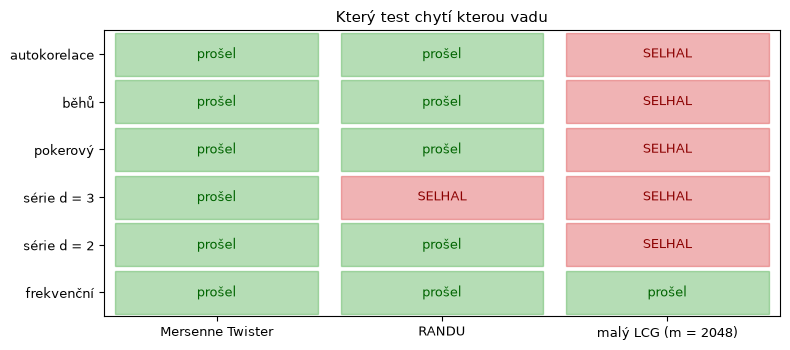

In [8]:
def vsechny_testy(xs):
    out = {}
    out["frekvenční"] = frekvencni_test(xs)[1]
    out["série d = 2"] = test_serii(xs, d=2, k=12)[1]
    out["série d = 3"] = test_serii(xs, d=3, k=8)[1]
    out["pokerový"] = pokerovy_test(xs)[0][1]
    out["běhů"] = test_behu(xs)[3]
    out["autokorelace"] = autokorelace(xs, 1)[2]
    return out


vysledky = {nazev: vsechny_testy(VZORKY[nazev]) for nazev, _ in GENERATORY}
nazvy_testu = list(vysledky["Mersenne Twister"])

print(f"{'test':16s}" + "".join(f"{n[:18]:>20s}" for n, _ in GENERATORY))
for t in nazvy_testu:
    radek = ""
    for nazev, _ in GENERATORY:
        p = vysledky[nazev][t]
        radek += f"{('p = ' + format(p, '.4f')) if p >= 1e-4 else 'p < 0.0001':>20s}"
    print(f"{t:16s}{radek}")

fig, ax = plt.subplots(figsize=(8, 3.6))
for j, (nazev, _) in enumerate(GENERATORY):
    for i, t in enumerate(nazvy_testu):
        p = vysledky[nazev][t]
        ok = p > 0.01
        ax.add_patch(plt.Rectangle((j - 0.45, i - 0.45), 0.9, 0.9,
                                   color="tab:green" if ok else "tab:red", alpha=0.35))
        ax.text(j, i, "prošel" if ok else "SELHAL", ha="center", va="center",
                fontsize=9, color="darkgreen" if ok else "darkred")
ax.set_xticks(range(len(GENERATORY)))
ax.set_xticklabels([n for n, _ in GENERATORY], fontsize=9)
ax.set_yticks(range(len(nazvy_testu)))
ax.set_yticklabels(nazvy_testu, fontsize=9)
ax.set_xlim(-0.5, len(GENERATORY) - 0.5)
ax.set_ylim(-0.5, len(nazvy_testu) - 0.5)
ax.set_title("Který test chytí kterou vadu", fontsize=11)
plt.tight_layout()
plt.show()

Tabulka shrnuje celou pointu:

- **Malý LCG** selže skoro všude — takovou vadu najde kdokoli.
- **RANDU** projde frekvenčním, pokerovým i dvourozměrným testem sérií. Padne až na **trojrozměrném** testu sérií. Kdo testoval do dvou rozměrů, nic nenašel.
- **Mersenne Twister** projde vším, co jsme na něj pustili. Což neznamená, že je bez vady — znamená to, že tyhle testy ji nevidí. (MT19937 skutečně selhává na některých testech z baterie TestU01, jen jsou jemnější než naše.)

## 9. Test druhého řádu

Jeden test na jedné posloupnosti dá jedno číslo, a to může vyjít podezřele i u dokonalého generátoru — v jednom případě ze sta při hranici $0.01$. Pořádně se testuje tak, že test pustíme na mnoho nezávislých úseků a podíváme se na **rozdělení p-hodnot**. Za $H_0$ mají být rovnoměrné na $[0,1)$.

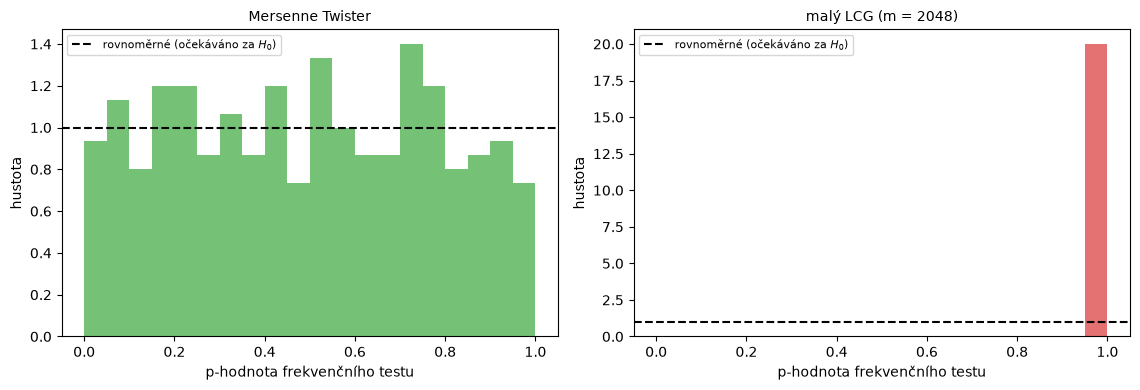

U dobrého generátoru je histogram p-hodnot plochý.
U špatného se hromadí u nuly — test ho odmítá skoro pokaždé.


In [9]:
def p_hodnoty(gen_f, bloku=300, delka=2000, k=20):
    out = []
    for _ in range(bloku):
        out.append(frekvencni_test(gen_f(delka), k=k)[1])
    return out


fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, (nazev, f) in zip(axes, (("Mersenne Twister", mt), ("malý LCG (m = 2048)", lcg_maly))):
    ps = p_hodnoty(f)
    ax.hist(ps, bins=20, range=(0, 1), density=True, alpha=0.65,
            color="tab:green" if "Twister" in nazev else "tab:red")
    ax.axhline(1.0, color="k", ls="--", label="rovnoměrné (očekáváno za $H_0$)")
    ax.set_xlabel("p-hodnota frekvenčního testu")
    ax.set_ylabel("hustota")
    ax.set_title(nazev, fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("U dobrého generátoru je histogram p-hodnot plochý.")
print("U špatného se hromadí u nuly — test ho odmítá skoro pokaždé.")

## Shrnutí

| Test | Co měří | Co chytí |
|------|---------|----------|
| frekvenční | rovnoměrnost hodnot | hrubou nerovnoměrnost, malý modul |
| série, $d = 2$ | nezávislost dvojic | mřížku viditelnou v rovině |
| série, $d = 3$ | nezávislost trojic | **RANDU** a jeho 15 rovin |
| pokerový | opakování v pětici | zúžený obor hodnot |
| běhů | pořadí, ne hodnoty | trend, periodicitu |
| autokorelační | lineární závislost na odstup $\ell$ | krátkodobou paměť |
| druhého řádu | rozdělení p-hodnot | systematické odchylky, které jeden běh neukáže |

Tři věci, které si odnést:

1. **χ² je společný tvar.** Roztřiď do přihrádek, porovnej s očekáváním, spočítej p-hodnotu.
2. **„Prošel" znamená jen „tenhle test tuhle vadu nevidí."** RANDU prošel vším kromě jediného testu — a ten jediný stačil.
3. **Testuj ve víc rozměrech, než si myslíš, že potřebuješ.** Vada se schová do dimenze, kterou netestuješ, a vyleze přesně tehdy, když v ní poběží simulace.

### Zkuste si

1. Pusťte trojrozměrný test sérií na RANDU s $k = 4$ místo $8$. Projde? Proč hrubší dělení vadu schová?
2. Doplňte čtyřrozměrný test sérií. Kolik vzorků potřebujete, aby bylo každé $E_i$ aspoň 5?
3. Napište test „mezer" (gap test): sledujte délky mezer mezi návštěvami intervalu $(\alpha, \beta)$; mají geometrické rozdělení. Chytí RANDU?
4. Vezměte generátor, který vrací `(i % 1000) / 1000` pro rostoucí `i`. Který z našich testů ho odhalí jako první?
5. Pusťte test druhého řádu na RANDU s trojrozměrným testem sérií a nakreslete histogram p-hodnot. Jak vypadá naprosté selhání?